In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path().resolve().parent / "src"))

import matplotlib.pyplot as plt

from results import ModelResults, ModelComparison, build_dataset, combine_model_comparisons

In [3]:
dataset = build_dataset()
no_cache_results = ModelResults('024-baseline-1', 'ddpm-1000', epoch=99, dataset_split='test', dataset=dataset)
basic_caching_results = ModelResults('024-baseline-1', 'ddpm-cache-struc-1000', epoch=99, dataset_split='test', dataset=dataset)

basic_cache_comparison = ModelComparison([no_cache_results, basic_caching_results], ['No Caching', 'Basic Caching'])

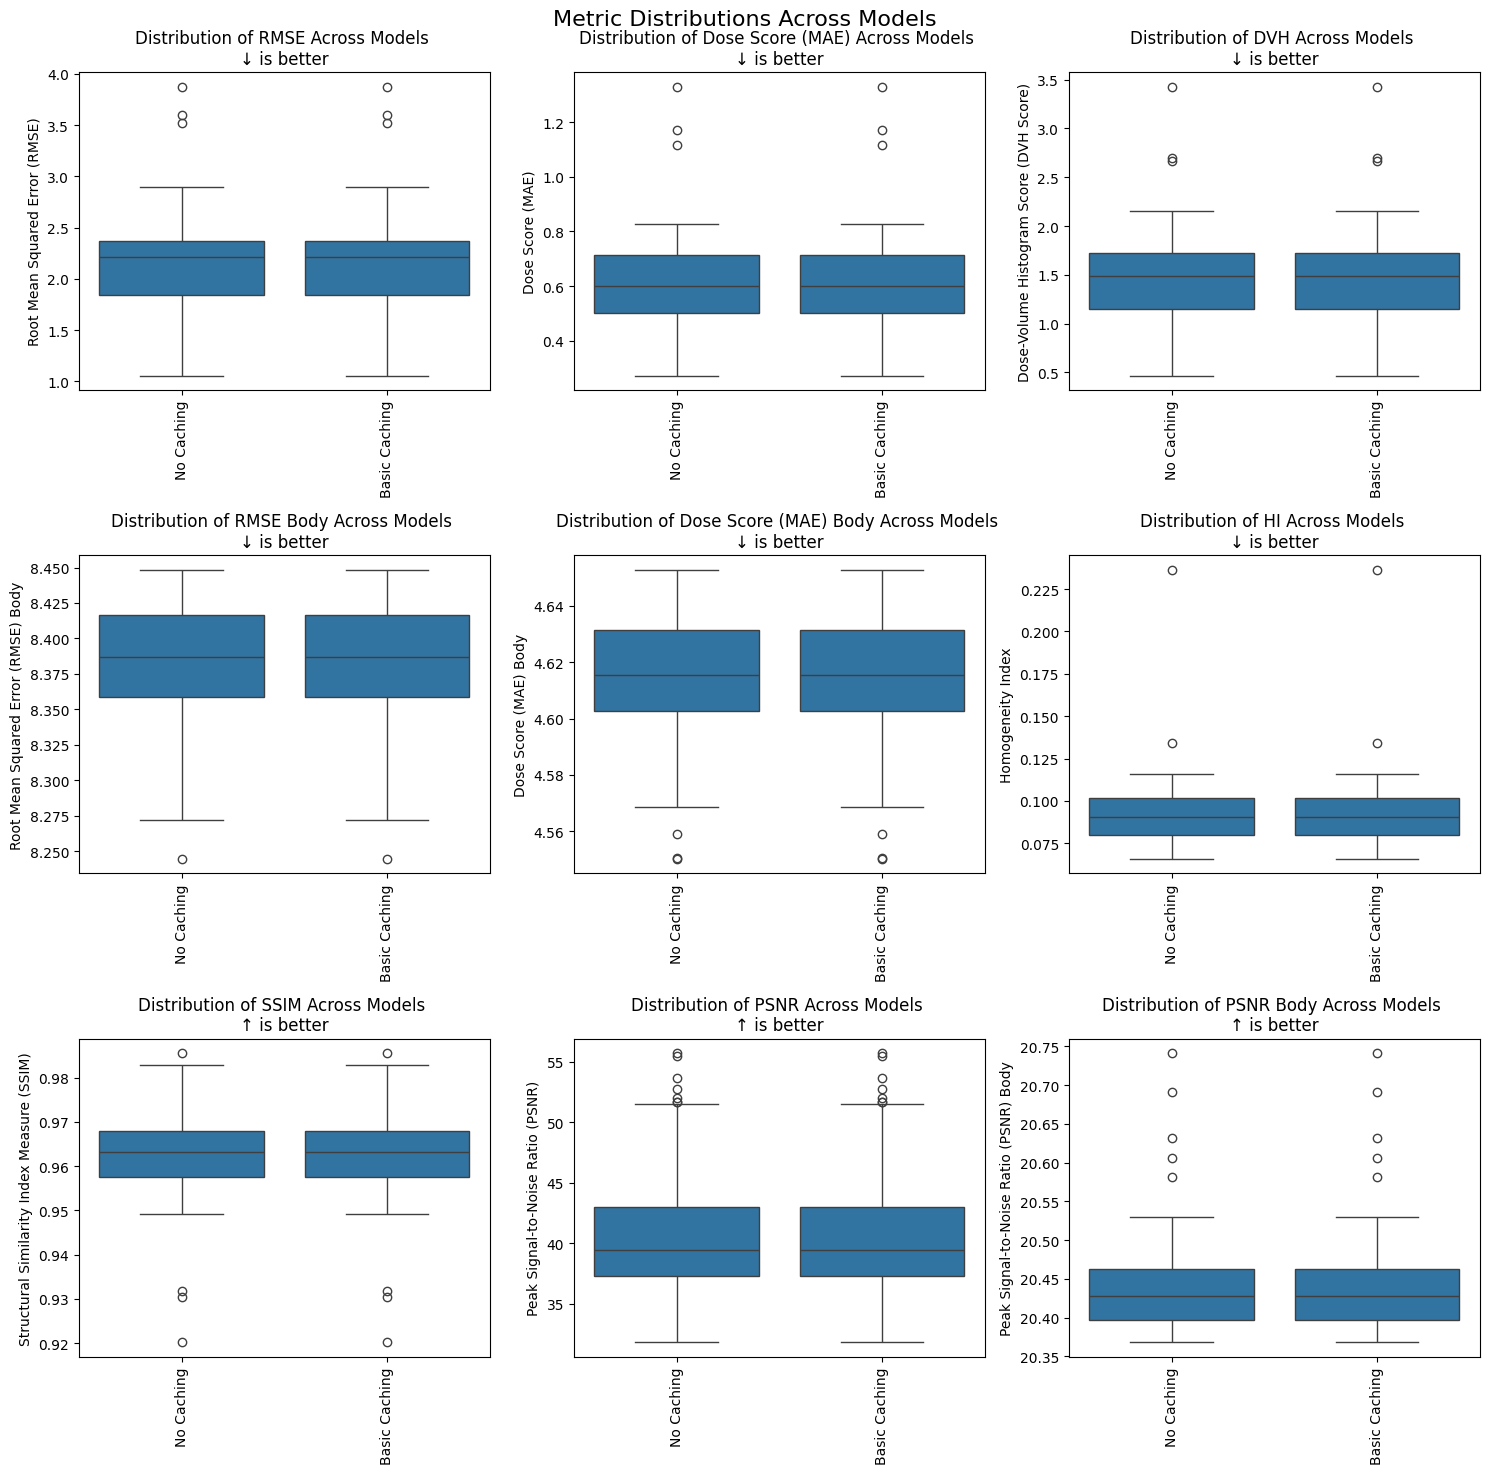

In [4]:
ax = basic_cache_comparison.plot_metric_distributions()

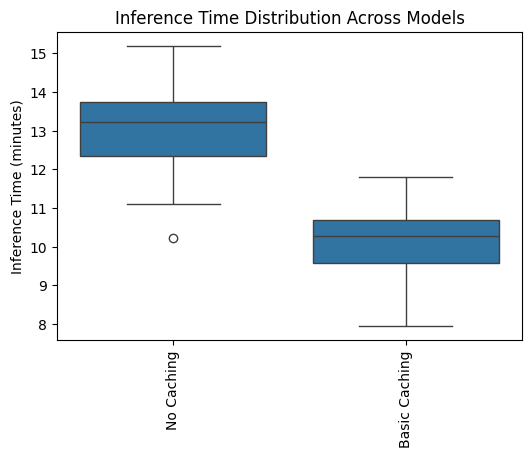

In [5]:
ax = basic_cache_comparison.plot_inference_times()

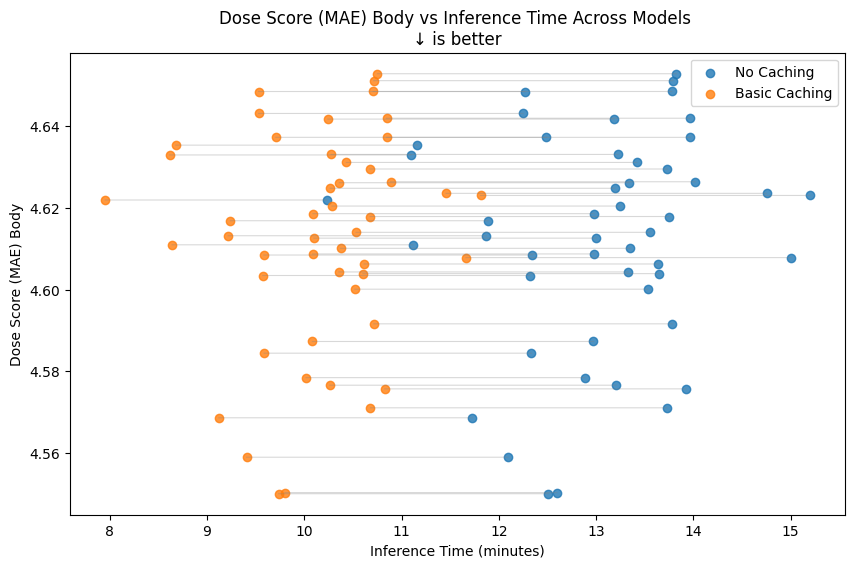

In [6]:
ax = basic_cache_comparison.plot_quality_over_time_by_volume('dose_score_body')

## DeepCache

### Encoder 1-4

In [12]:
enc1_int3_results = ModelResults('024-baseline-1', 'ddpm-cache-enc1-interval3-1000', epoch=99, dataset_split='test', dataset=dataset)
enc1_int5_results = ModelResults('024-baseline-1', 'ddpm-cache-enc1-interval5-1000', epoch=99, dataset_split='test', dataset=dataset)
enc1_int10_results = ModelResults('024-baseline-1', 'ddpm-cache-enc1-interval10-1000', epoch=99, dataset_split='test', dataset=dataset)
enc1_int20_results = ModelResults('024-baseline-1', 'ddpm-cache-enc1-interval20-1000', epoch=99, dataset_split='test', dataset=dataset)
enc1_nonuni10_results = ModelResults('024-baseline-1', 'ddpm-cache-enc1-nonuni10-1000', epoch=99, dataset_split='test', dataset=dataset)
enc1_nonuni20_results = ModelResults('024-baseline-1', 'ddpm-cache-enc1-nonuni20-1000', epoch=99, dataset_split='test', dataset=dataset)

enc1_comparison = ModelComparison(
    [
        basic_caching_results,
        enc1_int3_results,
        enc1_int5_results,
        enc1_int10_results,
        enc1_int20_results,
        # enc1_nonuni10_results,
        # enc1_nonuni20_results,
    ],
    [
        'Basic Caching',
        'Uniform T=3',
        'Uniform T=5',
        'Uniform T=10',
        'Uniform T=20',
        # 'Non-Uniform - N=10',
        # 'Non-Uniform - N=20',
    ]
)

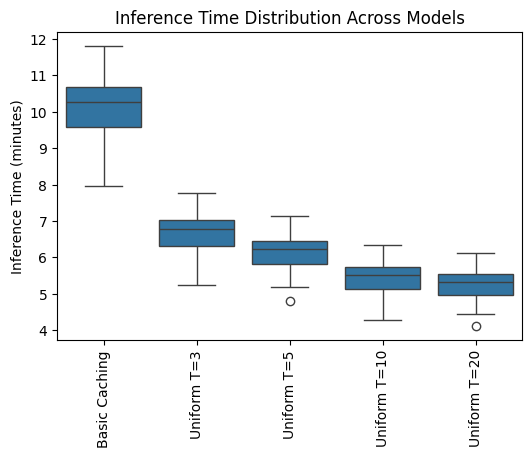

In [13]:
ax = enc1_comparison.plot_inference_times()

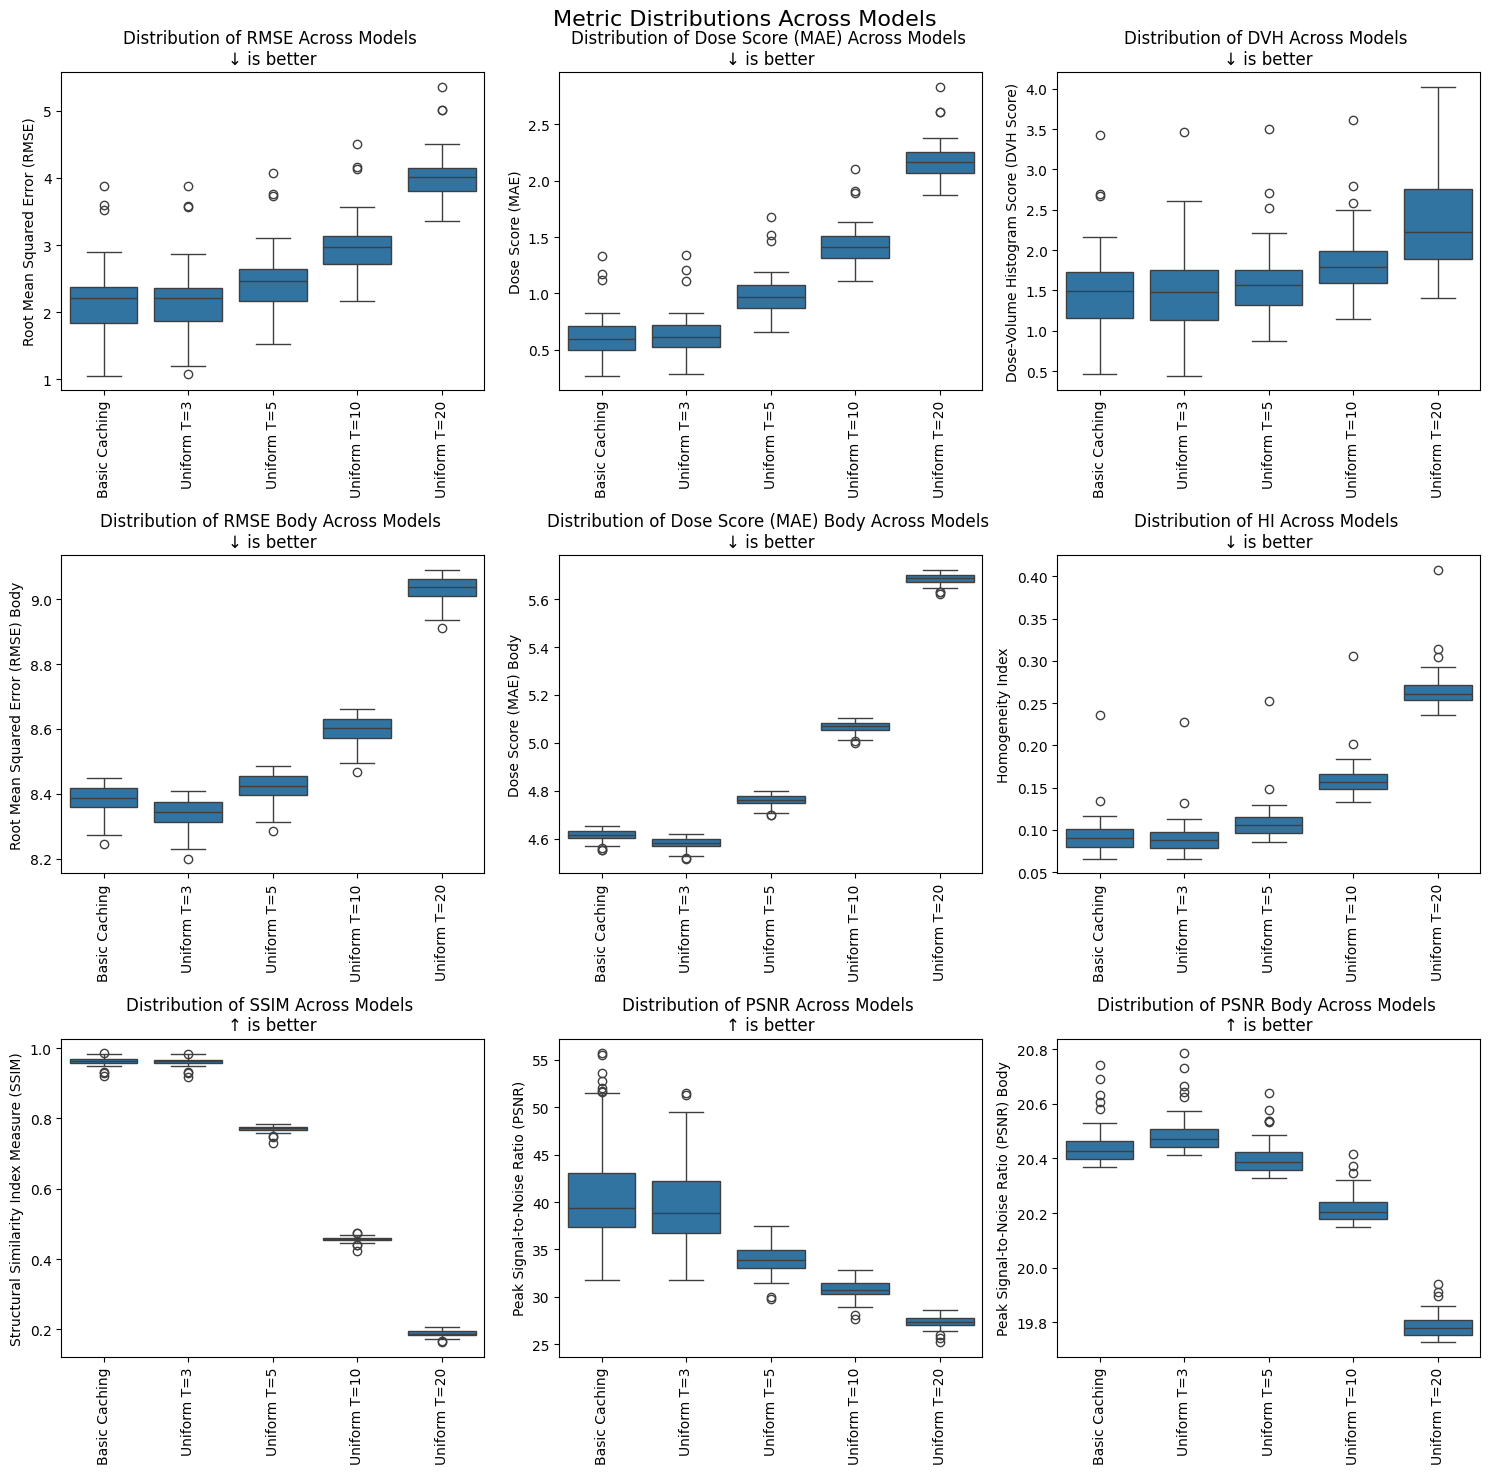

In [14]:
ax = enc1_comparison.plot_metric_distributions()

### Encoder 2-4

In [ ]:
enc2_int3_results = ModelResults('024-baseline-1', 'ddpm-cache-enc2-interval3-1000', epoch=99, dataset_split='test', dataset=dataset)
enc2_int5_results = ModelResults('024-baseline-1', 'ddpm-cache-enc2-interval5-1000', epoch=99, dataset_split='test', dataset=dataset)
enc2_int10_results = ModelResults('024-baseline-1', 'ddpm-cache-enc2-interval10-1000', epoch=99, dataset_split='test', dataset=dataset)
enc2_int20_results = ModelResults('024-baseline-1', 'ddpm-cache-enc2-interval20-1000', epoch=99, dataset_split='test', dataset=dataset)

enc2_comparison = ModelComparison(
    [
        basic_caching_results,
        enc2_int3_results,
        enc2_int5_results,
        enc2_int10_results,
        enc2_int20_results,
    ],
	  [
        'Basic Caching',
        'Uniform T=3',
        'Uniform T=5',
        'Uniform T=10',
        'Uniform T=20',
    ]
)


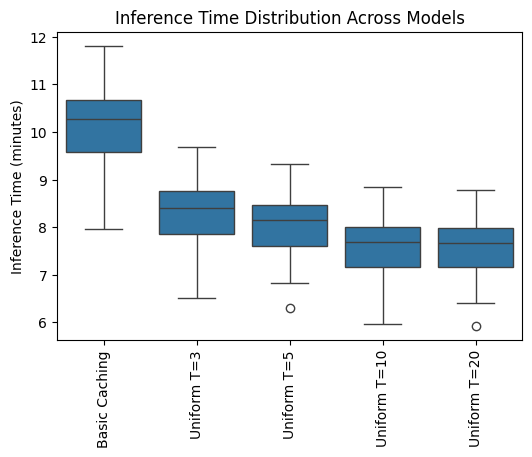

In [24]:
ax = enc2_comparison.plot_inference_times()

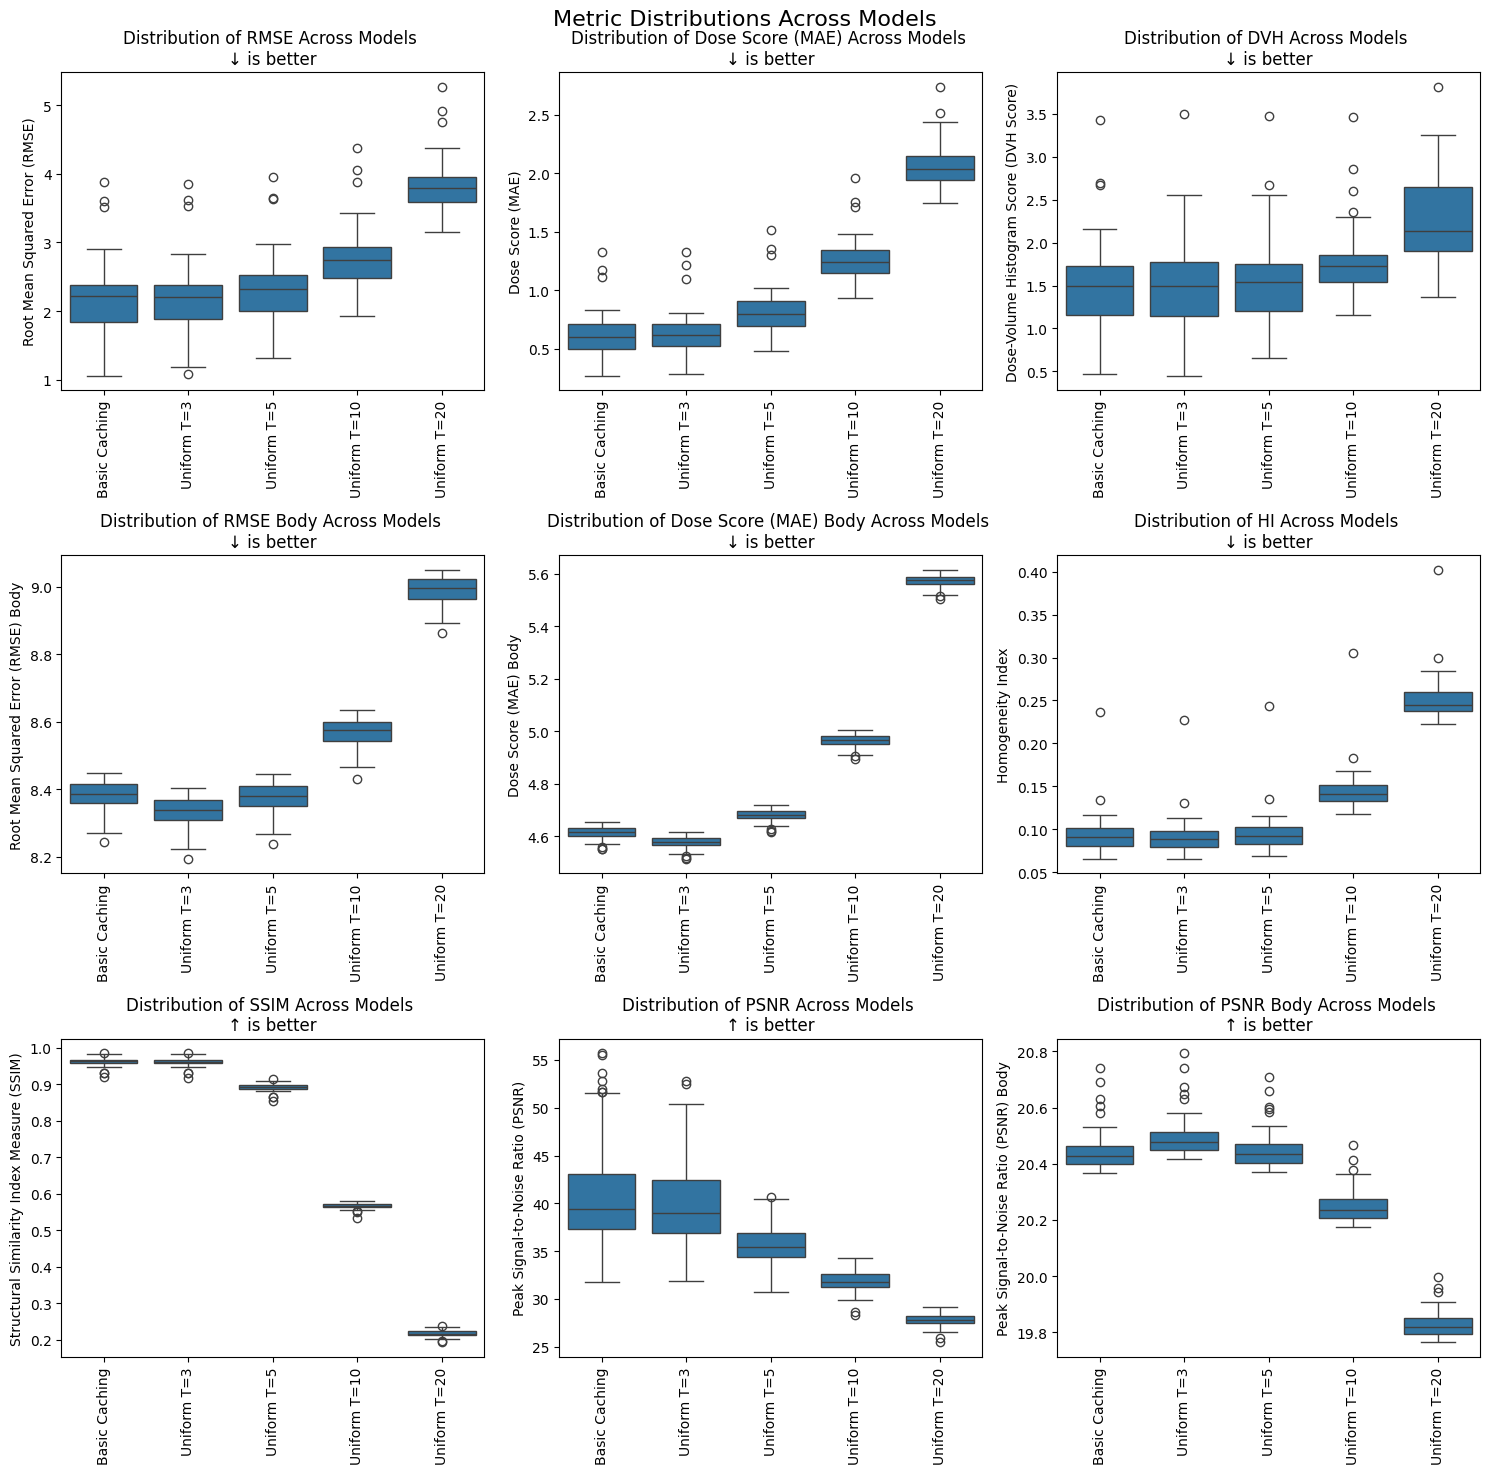

In [18]:
ax = enc2_comparison.plot_metric_distributions()

### Encoders 3-4

In [19]:
enc3_int3_results = ModelResults('024-baseline-1', 'ddpm-cache-enc3-interval3-1000', epoch=99, dataset_split='test', dataset=dataset)
enc3_int5_results = ModelResults('024-baseline-1', 'ddpm-cache-enc3-interval5-1000', epoch=99, dataset_split='test', dataset=dataset)
enc3_int10_results = ModelResults('024-baseline-1', 'ddpm-cache-enc3-interval10-1000', epoch=99, dataset_split='test', dataset=dataset)
enc3_int20_results = ModelResults('024-baseline-1', 'ddpm-cache-enc3-interval20-1000', epoch=99, dataset_split='test', dataset=dataset)

enc3_comparison = ModelComparison(
    [
        basic_caching_results,
        enc3_int3_results,
        enc3_int5_results,
        enc3_int10_results,
        enc3_int20_results,
    ],
	  [
        'Basic Caching',
        'Uniform T=3',
        'Uniform T=5',
        'Uniform T=10',
        'Uniform T=20',
    ]
)


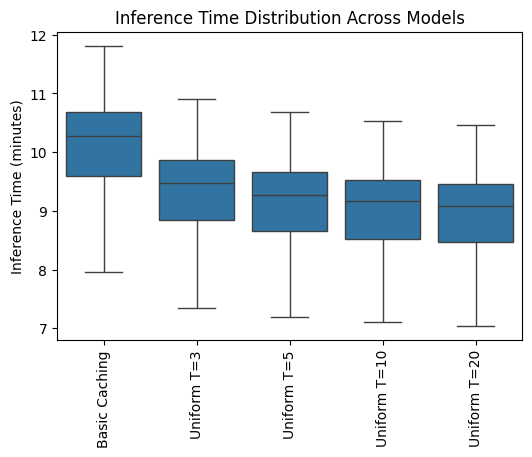

In [22]:
ax = enc3_comparison.plot_inference_times()

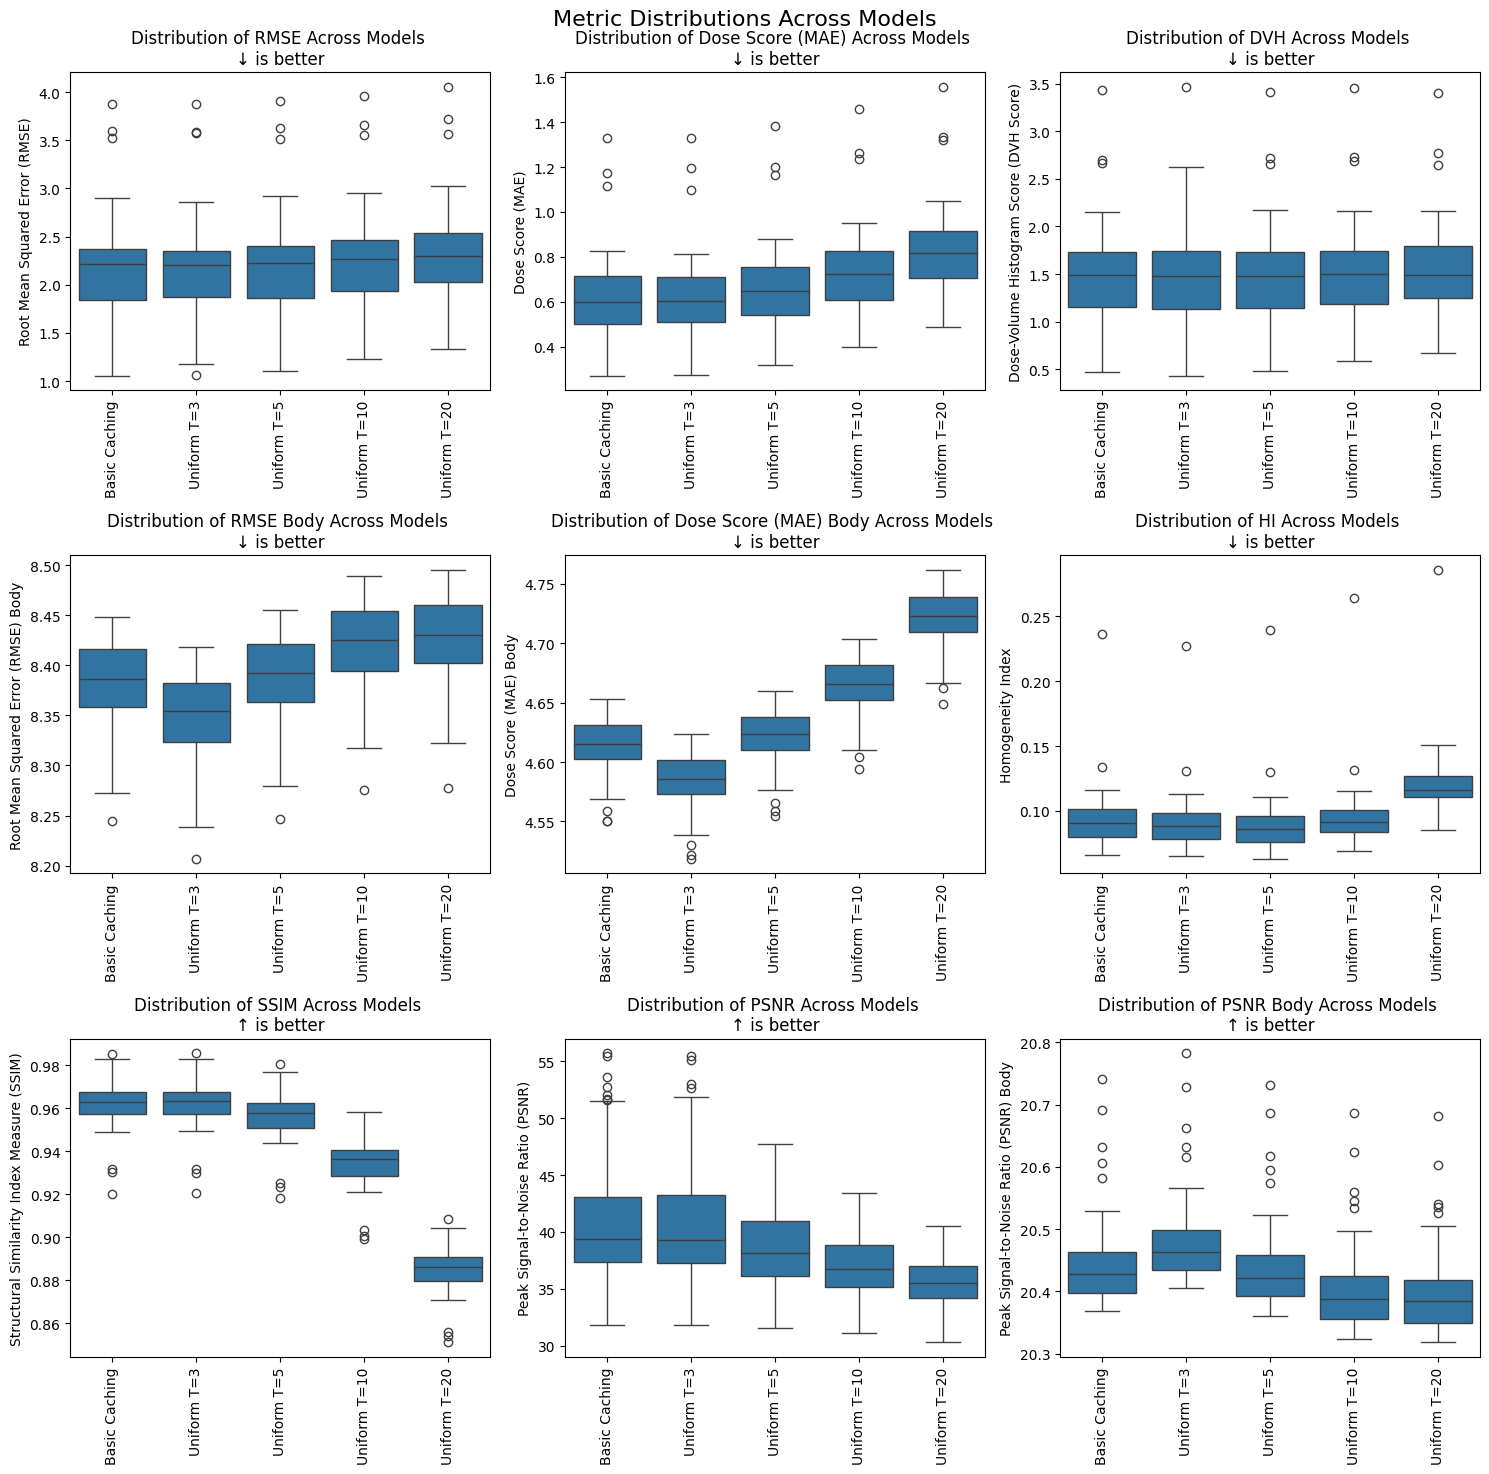

In [23]:
ax = enc3_comparison.plot_metric_distributions()

### Encoder 4

In [25]:
enc4_int3_results = ModelResults('024-baseline-1', 'ddpm-cache-enc4-interval3-1000', epoch=99, dataset_split='test', dataset=dataset)
enc4_int5_results = ModelResults('024-baseline-1', 'ddpm-cache-enc4-interval5-1000', epoch=99, dataset_split='test', dataset=dataset)
enc4_int10_results = ModelResults('024-baseline-1', 'ddpm-cache-enc4-interval10-1000', epoch=99, dataset_split='test', dataset=dataset)
enc4_int20_results = ModelResults('024-baseline-1', 'ddpm-cache-enc4-interval20-1000', epoch=99, dataset_split='test', dataset=dataset)

enc4_comparison = ModelComparison(
    [
        basic_caching_results,
        enc4_int3_results,
        enc4_int5_results,
        enc4_int10_results,
        enc4_int20_results,
    ],
	  [
        'Basic Caching',
        'Uniform T=3',
        'Uniform T=5',
        'Uniform T=10',
        'Uniform T=20',
    ]
)


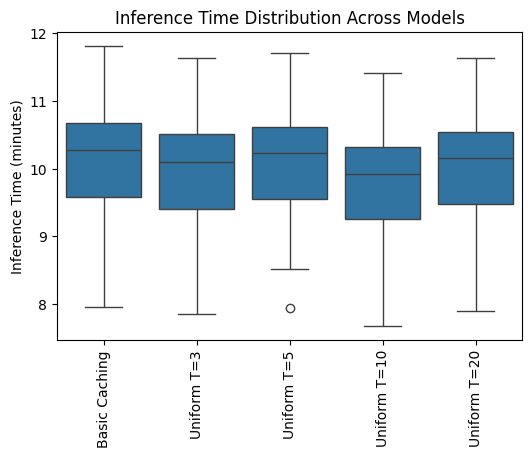

In [28]:
ax = enc4_comparison.plot_inference_times()

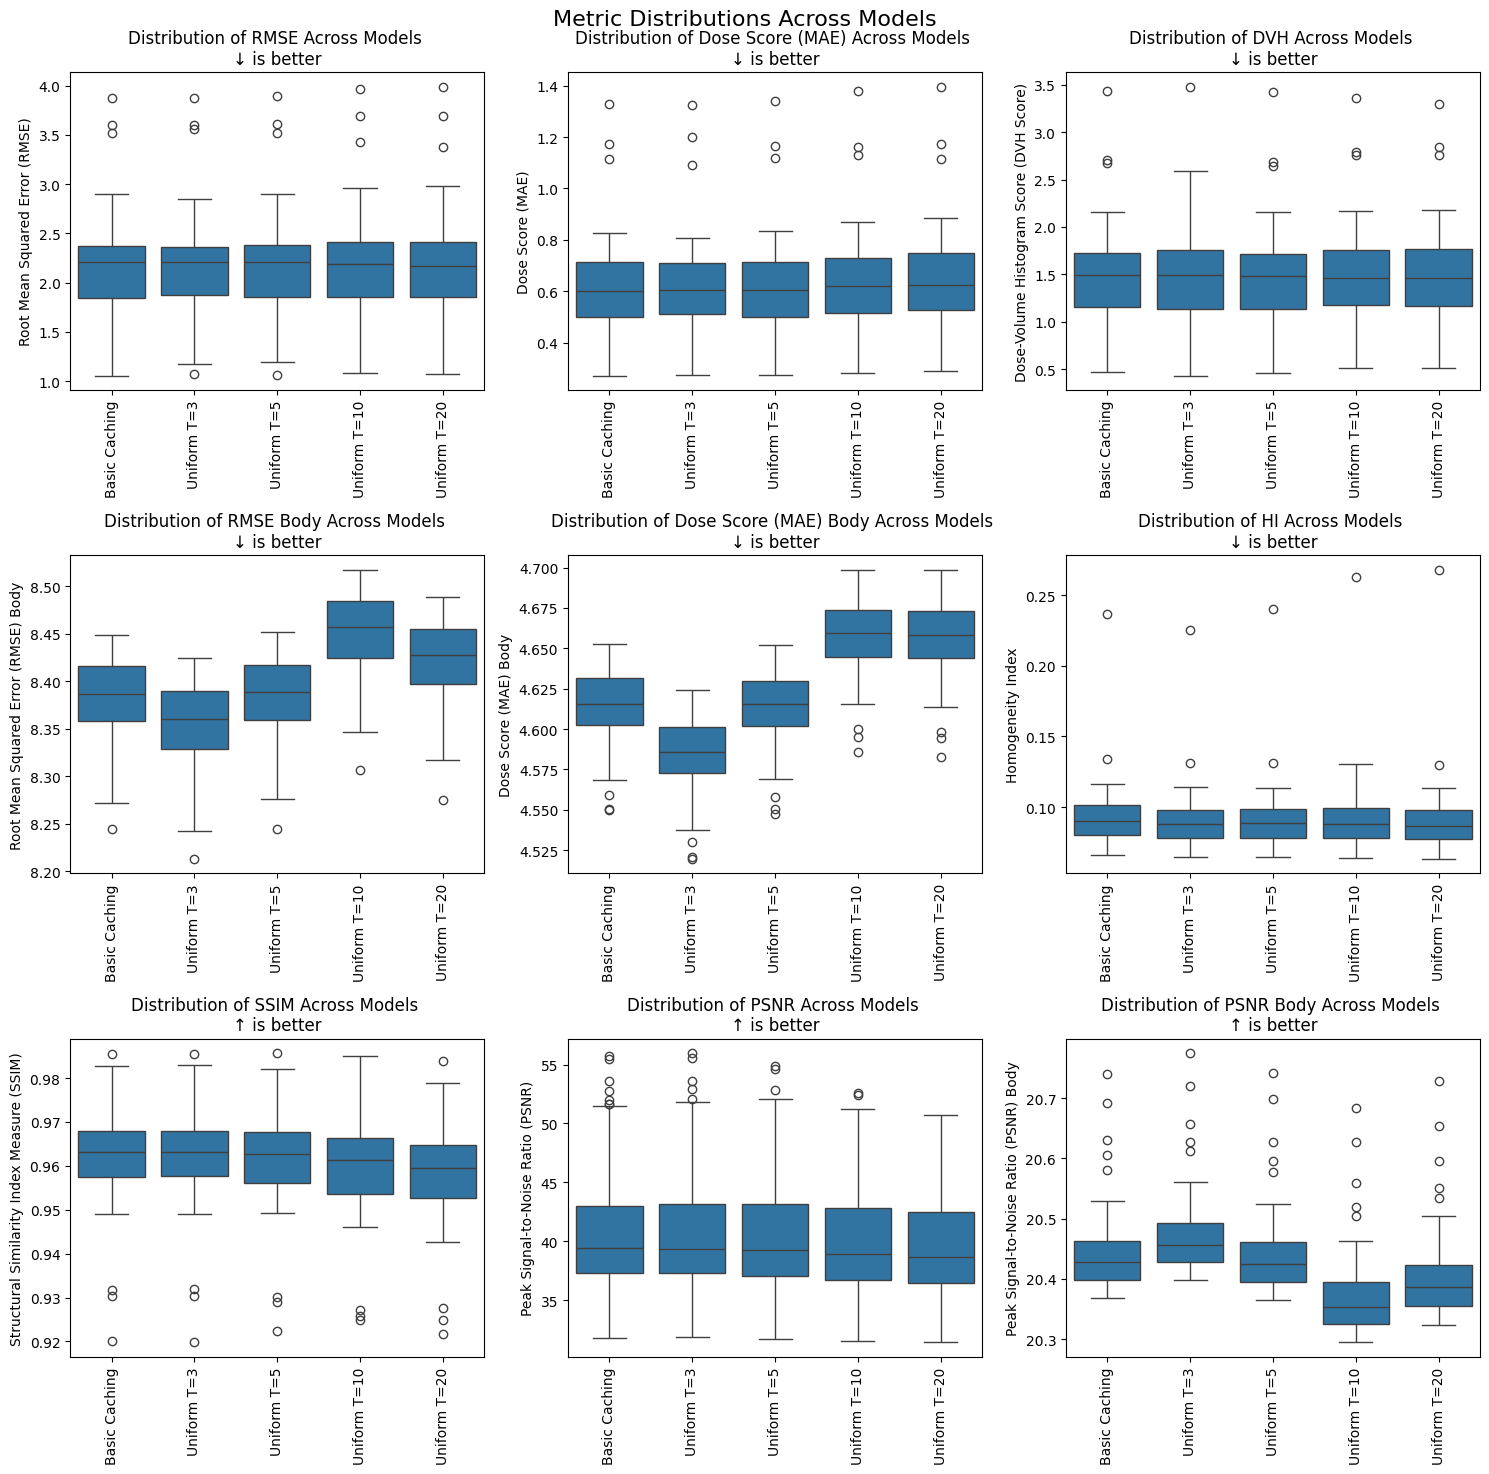

In [29]:
ax = enc4_comparison.plot_metric_distributions()

## All Variants

In [34]:
comparison = combine_model_comparisons([
    enc1_comparison,
    enc2_comparison,
    enc3_comparison,
    enc4_comparison,
], ['Enc 1-4', 'Enc 2-4', 'Enc 3-4', 'Enc 4'])

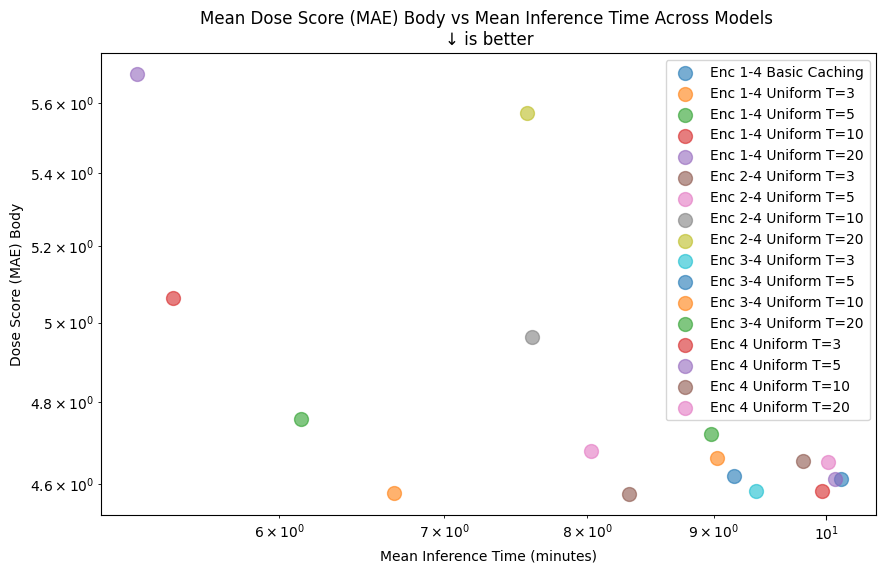

In [35]:
ax = comparison.plot_quality_over_time('dose_score_body')
_ = ax.set_yscale('log')
_ = ax.set_xscale('log')